# Day 6 — Advanced Seaborn for Analytical Visualization

## Objective

The objective of this notebook is to move beyond basic visualization and develop the ability to perform **multi-variable analysis using visual tools**. The focus is not only on creating plots, but on extracting meaningful insights and understanding relationships within data.

---

## What This Notebook Covers

- Performing grouped analysis using advanced visualization techniques  
- Exploring relationships between multiple variables  
- Using automated tools to analyze entire datasets efficiently  
- Understanding and interpreting correlation between variables  
- Analyzing categorical data through frequency-based visualizations  
- Gaining deeper insight into data distributions and patterns  

---

## Analytical Focus

This notebook emphasizes answering deeper analytical questions such as:

- How do different groups behave within the same dataset?  
- Are multiple variables related, and how strong is that relationship?  
- Which variables move together, and which behave independently?  
- What hidden patterns or clusters exist in the data?  

---

## Learning Outcome

By the end of this notebook, you will be able to:

- Analyze multi-dimensional datasets using Seaborn  
- Identify relationships and correlations between variables  
- Perform grouped comparisons within a single visualization  
- Interpret visual patterns and convert them into meaningful insights  

---

## Key Shift

From:

Creating individual plots for basic understanding  

To:

Using visualization as a tool for **deep analytical reasoning and decision-making**

---

## Final Perspective

This notebook represents the transition from visualization as a skill to visualization as an analytical tool. The focus is on thinking like a data analyst—using visuals not just to display data, but to uncover patterns, validate assumptions, and support decisions.

# **1. Grouped Analysis with `hue` (VERY IMPORTANT)**

---

## 1. Why Grouped Analysis Matters

In real-world data analysis, you rarely analyze a single variable in isolation.

Most business questions involve **comparison across groups**:

- How do sales differ by region?
- Does customer behavior change by gender?
- Do product categories follow different trends?

If you create separate plots for each group, you lose clarity.

> A professional analyst compares groups **within the same visual context**

This is exactly what `hue` is designed for.

---

## 2. What is `hue`?

`hue` is a parameter in Seaborn that allows you to:

> Add a **third variable (category)** into the visualization using color

---

### Core Idea

Without `hue`:

- You plot relationship between X and Y

With `hue`:

- You plot relationship between X and Y
- AND compare categories within the same plot

---

### Mental Model

Without `hue`:

```text
Sales vs Time

##3. Basic Example (Line Plot with Grouping)

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "Day": [1, 2, 3, 4, 5, 1, 2, 3, 4, 5],
    "Sales": [10, 20, 15, 25, 30, 8, 18, 12, 22, 28],
    "Region": ["East"]*5 + ["West"]*5
})

##Without hue

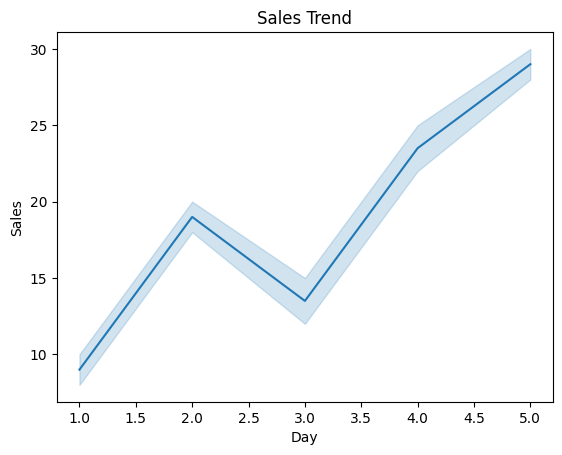

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(x="Day", y="Sales", data=df)

plt.title("Sales Trend")
plt.show()

##With hue

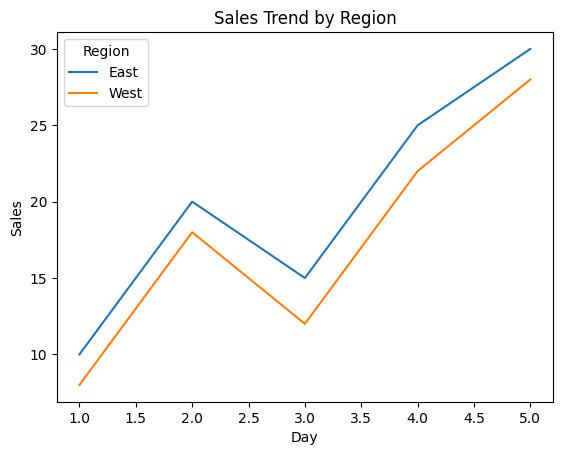

In [ ]:
sns.lineplot(x="Day", y="Sales", hue="Region", data=df)

plt.title("Sales Trend by Region")
plt.show()

##What Changed?
- Two lines are plotted instead of one
- Each color represents a region
- You can directly compare trends

##4. Applying hue to Different Plot Types
###4.1 Line Plot with hue (Trend Comparison)
###Use Case

Compare trends across groups

<Axes: xlabel='Day', ylabel='Sales'>

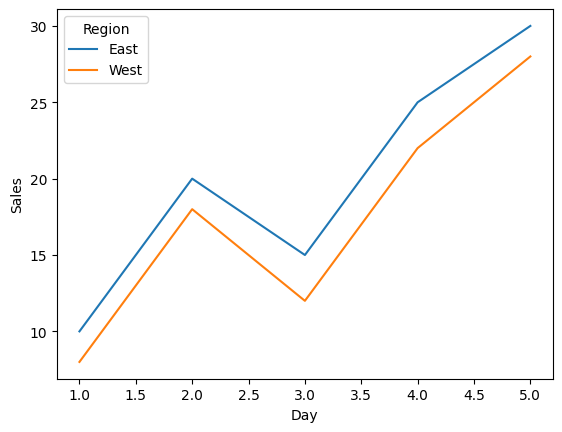

In [ ]:
sns.lineplot(x = 'Day', y = 'Sales', hue = 'Region', data = df)

###Insight
- Compare growth patterns across categories
- Identify divergence in trends

###4.2 Bar Plot with hue (Category Comparison within Groups)

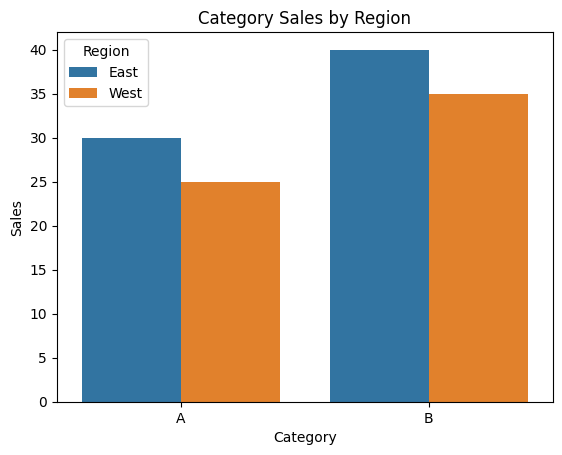

In [ ]:
df_bar = pd.DataFrame({
    "Category": ["A", "A", "B", "B"],
    "Region": ["East", "West", "East", "West"],
    "Sales": [30, 25, 40, 35]
})

sns.barplot(x = 'Category', y = 'Sales', hue = 'Region', data= df_bar)
plt.title("Category Sales by Region")
plt.show()

##Insight
- Compare regions within each category
- Identify which region dominates which category

###4.3 Scatter Plot with hue (Relationship + Grouping)

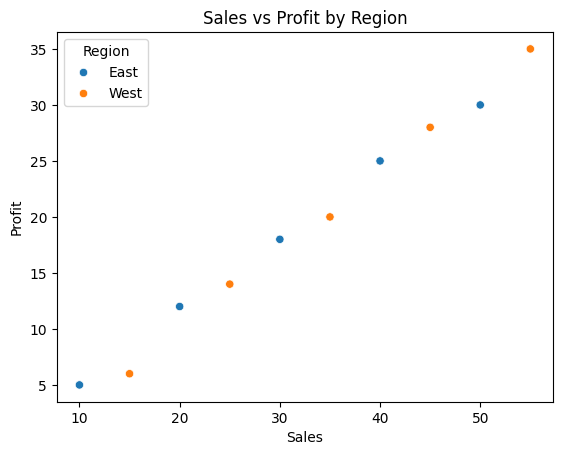

In [ ]:
df_scatter = pd.DataFrame({
    "Sales": [10, 20, 30, 40, 50, 15, 25, 35, 45, 55],
    "Profit": [5, 12, 18, 25, 30, 6, 14, 20, 28, 35],
    "Region": ["East"]*5 + ["West"]*5
})

sns.scatterplot(x = 'Sales', y = 'Profit', hue = 'Region', data = df_scatter)

plt.title("Sales vs Profit by Region")
plt.show()

##Insight
- Compare relationships across groups
- Detect if correlation differs by category
- Identify clusters

##5. How Seaborn Handles hue Internally

When you use:

`hue="Region"`

###Seaborn:

- separates data by category
- assigns different colors
- plots each group automatically
- adds legend for interpretation
##Key Advantage

- You do NOT manually split data.

- Seaborn does grouping for you.

##6. Choosing When to Use hue
###Use hue when:
- you want to compare groups in the same plot
- you have a categorical variable
- you want to avoid multiple separate charts
###Do NOT use hue when:
- too many categories (visual clutter)
- comparison becomes confusing

##7. Common Mistakes
###Mistake 1: Too many categories
Region = 10 categories → unreadable plot
###Mistake 2: Wrong variable in hue

Using numerical continuous variable in hue without purpose

###Mistake 3: Ignoring legend

Always interpret colors correctly

# **2. Multi-Variable Relationship Analysis**

---

## 1. Why Multi-Variable Analysis is Important

In real-world data analysis, problems are rarely simple.

You are not just analyzing:

- Sales vs Time  
- Profit vs Sales  

Instead, you are analyzing:

> How multiple variables interact together

Examples:

- How do **sales and profit change across regions**?
- Does the **relationship between variables change by category**?
- Are there **hidden clusters of behavior**?

---

## Core Idea

> Real insights come from understanding **interactions between multiple variables**

---

## 2. What is Multi-Variable Visualization?

---

##  Definition

Multi-variable analysis means:

> Visualizing **more than two variables** in a single plot

---

## Example

Instead of:

```text
Sales vs Profit

###You analyze:

Sales vs Profit across Regions

###Variables Involved

Variable Type	Example

X-axis	Sales

Y-axis	Profit

Category	Region (via hue)
###Key Insight

You are now analyzing:

- relationship (Sales vs Profit)
- AND grouping (Region)

##3. Techniques for Multi-Variable Visualization
###3.1 Using hue (Color Dimension)

Already learned, but now used strategically.

Example

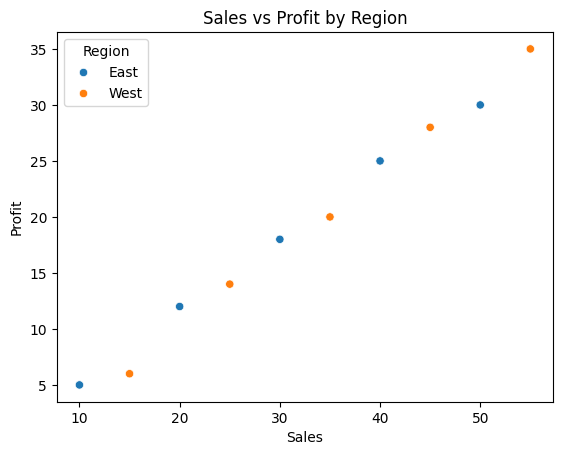

In [ ]:
df = pd.DataFrame({
    "Sales": [10, 20, 30, 40, 50, 15, 25, 35, 45, 55],
    "Profit": [5, 12, 18, 25, 30, 6, 14, 20, 28, 35],
    "Region": ["East"]*5 + ["West"]*5
})

sns.scatterplot(x="Sales", y="Profit", hue="Region", data=df)

plt.title("Sales vs Profit by Region")
plt.show()

###What you observe
- overall relationship between Sales and Profit
- differences between regions
- possible clustering

###3.2 Using Size (Optional Dimension)

You can represent a third variable using marker size

####Example

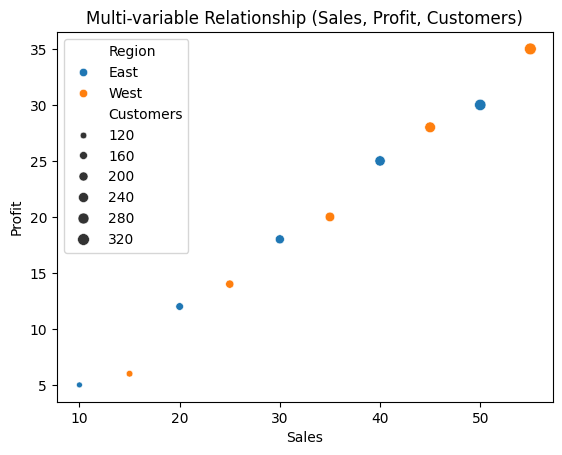

In [ ]:
df = pd.DataFrame({
    "Sales": [10, 20, 30, 40, 50, 15, 25, 35, 45, 55],
    "Profit": [5, 12, 18, 25, 30, 6, 14, 20, 28, 35],
    "Region": ["East"]*5 + ["West"]*5,
    "Customers": [100, 150, 200, 250, 300, 120, 170, 220, 270, 320]

})

sns.scatterplot(
    x="Sales",
    y="Profit",
    size="Customers",
    hue="Region",
    data=df
)

plt.title("Multi-variable Relationship (Sales, Profit, Customers)")
plt.show()

##“Where do these values come from?”
###Wrong Thinking

“We must decide values like 100, 150, 200 manually”

###Correct Thinking

These values come from real data
###Step 1: Look at your dataset
`df.columns`
###Step 2: Identify numerical columns

Example:

- Sales
- Profit
- Customers
- Revenue

###Step 3: Choose a meaningful variable for size
####Rule

Use size when:

- The variable represents magnitude or importance

##Insight

Now you are analyzing:

- Sales vs Profit
- Region differences
- Customer impact

## 4. Understanding Patterns Across Multiple Dimensions
What to look for
###1. Correlation Patterns
- Do variables move together?
- Is relationship strong or weak?
###2. Group Differences
- Do groups behave differently?
- Does one category outperform another?
###3. Clusters
- Are there natural groupings?
- Do points form separate regions?
###Example Thinking

“East region shows stronger profit growth compared to West”3

##5. Detecting Clusters and Group Behavior
### What is a cluster?

A cluster is:

- A group of points that behave similarly

###Example
- High sales + high profit group
- Low sales + low profit group
### Visual Identification

Clusters appear as:

- dense regions of points
- separated groups in scatter plot
###Analyst Insight

Clusters can indicate:

- customer segments
- product performance groups
- market behavior patterns

##6. Professional Interpretation Framework

When you see a multi-variable plot, ask:

1. Is there a relationship?
2. Do groups behave differently?
3. Are there clusters?
4. Is there any unusual pattern?

##7. Common Mistakes
###Mistake 1: Overloading the plot

Too many variables → confusion

###Mistake 2: Ignoring group differences

Looking only at overall trend

###Mistake 3: Misinterpreting patterns

Correlation ≠ causation

# **3. `pairplot()` — Automated Relationship Exploration**

---

## 1. Why `pairplot()` is Important

So far, you have been analyzing relationships manually:

- Sales vs Profit  
- Sales vs Customers  
- Profit vs Customers  

 But in real datasets, you may have **5, 10, or 20 variables**

Creating plots one by one becomes:

- slow  
- inefficient  
- incomplete  

---

##  Core Idea

> `pairplot()` automatically shows **all pairwise relationships** in a dataset

---

## 2. What is `pairplot()`?

---

##  Definition

`pairplot()` creates a grid of plots where:

- each variable is compared with every other variable  
- diagonal shows distribution of each variable  

---

##  Visual Structure

For variables: Sales, Profit, Customers

You get:

|       | Sales vs Sales | Sales vs Profit | Sales vs Customers |
|-------|---------------|----------------|-------------------|
| Profit | Profit vs Sales | Profit vs Profit | Profit vs Customers |
| Customers | Customers vs Sales | Customers vs Profit | Customers vs Customers |

---

##  Simplified Understanding

- Rows = one variable  
- Columns = another variable  
- Each cell = relationship  

---

## 3. Basic Example

---

##  Dataset

```python id="pairplot_data"
import seaborn as sns
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Sales": np.random.randint(10, 100, 50),
    "Profit": np.random.randint(5, 80, 50),
    "Customers": np.random.randint(50, 300, 50)
})

###Pairplot
`sns.pairplot(df)`

`plt.show()`

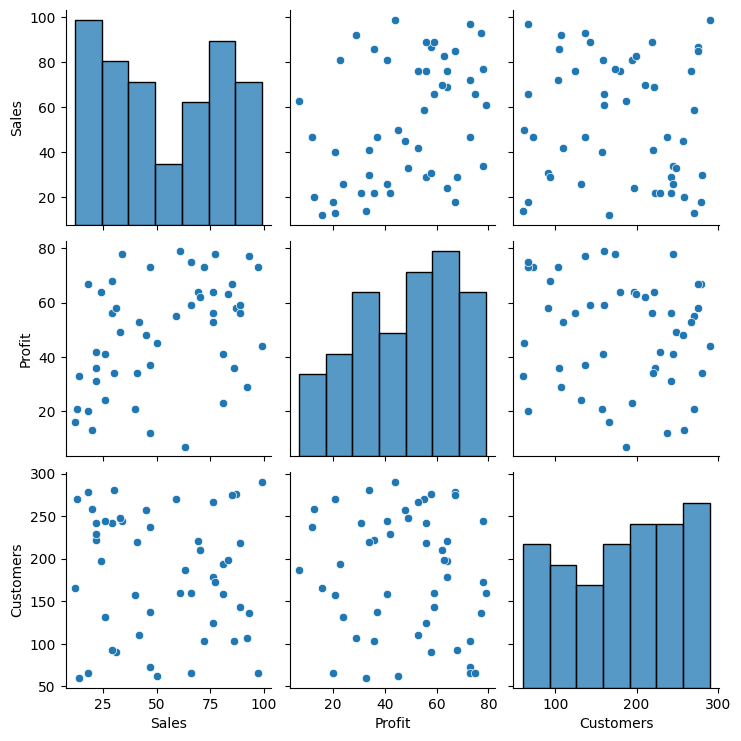

In [ ]:
import numpy as np

df = pd.DataFrame({
    "Sales": np.random.randint(10, 100, 50),
    "Profit": np.random.randint(5, 80, 50),
    "Customers": np.random.randint(50, 300, 50)
})

sns.pairplot(df)

plt.show()

##4. Understanding the Diagonal
### What is diagonal?

These are plots where:

- Sales vs Sales
- Profit vs Profit
- Customers vs Customers
###What is shown?

Distribution of each variable

###Insight from diagonal
- Are values spread out?
- Are values concentrated?
- Is data skewed?

##5. What to Look For in pairplot()
###1. Correlations

Do variables move together?

- upward pattern → positive correlation
- downward pattern → negative correlation
### 2. Clusters

Do points form groups?

- separate clusters → different behaviors
- dense groups → similar patterns
### 3. Trends

Is there a pattern?

- linear
- non-linear
- no relationship

##6. Adding Grouping with hue
### Purpose

To compare relationships across categories

### Example

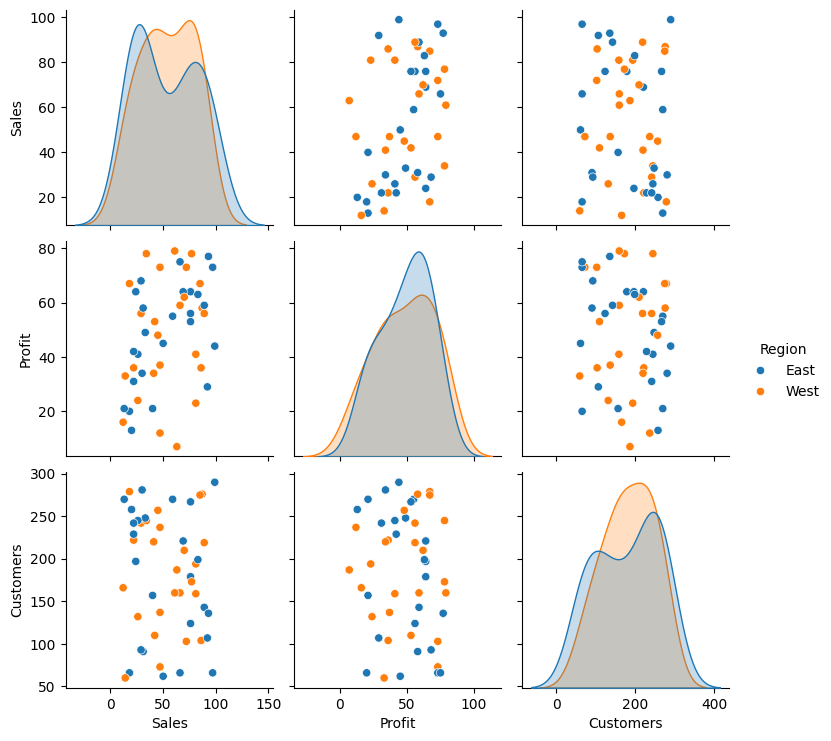

In [ ]:
df["Region"] = ["East", "West"] * 25

sns.pairplot(df, hue="Region")
plt.show()

###What changes?
- points are color-coded
- relationships compared across groups
###Insight
- Do regions behave differently?
- Do clusters vary by category?

##7. When to Use pairplot()
### Use when:
- exploring a new dataset
- finding relationships quickly
- identifying important variables
### Avoid when:
- dataset has too many variables (too crowded)
- dataset is very large (slow)

##8. Common Mistakes
### Mistake 1: Ignoring diagonal

Most beginners only look at scatter plots

 Distribution is equally important

### Mistake 2: Over-interpreting noise

Not every pattern is meaningful

### Mistake 3: Too many variables

More than 5–6 variables → messy output

# Understanding `pairplot()` — Function, Purpose, and Usage

---

## 1. What is the Function of `pairplot()`?

`pairplot()` is used to:

> Automatically visualize **relationships between all numerical variables** in a dataset

---

##  In simple terms

Instead of plotting:

- Sales vs Profit  
- Sales vs Customers  
- Profit vs Customers  

 One by one

`pairplot()` does:

> ALL of them at once in a single structured grid

---

##  Core Function

- Shows **pairwise relationships (scatter plots)**
- Shows **distribution of each variable (diagonal plots)**

---

## 2. Why Do We Use `pairplot()`?

---

##  Problem Without It

When you have multiple variables:

- You don’t know which variables are related  
- You don’t know where patterns exist  
- Manual plotting is slow  

---

##  Solution

`pairplot()` gives:

- quick overview of dataset  
- instant detection of patterns  
- faster exploration  

---

##  Key Purpose

> To quickly **understand the structure of your data**

---

## 3. When Should You Use `pairplot()`?

---

##  Use it when:

- You are exploring a **new dataset**
- You want to check **relationships between variables**
- You want to detect:
  - correlations  
  - clusters  
  - patterns  

---

##  Avoid it when:

- dataset has too many variables (messy output)  
- dataset is very large (slow performance)  

---

## 4. What is the Use of `pairplot()` in Real Analysis?

---

##  Real Workflow

When you get a dataset:

### Step 1:

```python
sns.pairplot(df)

###Step 2: Observe

You identify:

- which variables are related
- which variables are important
- where patterns exist
###Step 3:

- Focus only on important relationships

##5. What Insights Does It Give?
### Relationships
- positive correlation
- negative correlation
- no relationship
### Distribution
- spread of data
- skewness
- concentration
### Clusters
- groups of similar points
- different behaviors

####pairplot() is used to quickly explore and understand relationships between all variables in a dataset

# **4. `heatmap()` — Correlation Analysis**

---

## 1. Why Correlation Analysis Matters

In real-world data analysis, one of the most important questions is:

> “Which variables are related to each other?”

Examples:

- Does advertising increase sales?  
- Does customer count affect revenue?  
- Are profit and sales strongly connected?  

---

##  Core Idea

> Correlation analysis helps you **measure relationships between variables**

---

## 2. What is Correlation?

---

###  Definition

Correlation tells you:

> How strongly two variables move together

---

###  Correlation Values

| Value | Meaning |
|------|--------|
| +1   | Strong positive relationship |
| 0    | No relationship |
| -1   | Strong negative relationship |

---

###  Interpretation

- **Positive correlation** → both increase together  
- **Negative correlation** → one increases, other decreases  
- **Zero correlation** → no relationship  

---

## 3. What is a Heatmap?

---

###  Definition

A heatmap is:

> A visual representation of values using colors

---

###  In this context

It shows:

> Correlation between all variables in a dataset

---

###  Example Output

- Each cell = correlation between two variables  
- Color intensity = strength of relationship  

---

## 4. Creating a Correlation Matrix

---

##  Step 1: Dataset

```python id="heatmap_data"
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Sales": np.random.randint(10, 100, 50),
    "Profit": np.random.randint(5, 80, 50),
    "Customers": np.random.randint(50, 300, 50),
    "Advertising": np.random.randint(20, 200, 50)
})

In [ ]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Sales": np.random.randint(10, 100, 50),
    "Profit": np.random.randint(5, 80, 50),
    "Customers": np.random.randint(50, 300, 50),
    "Advertising": np.random.randint(20, 200, 50)
})

corr = df.corr()
print(corr)

                Sales    Profit  Customers  Advertising
Sales        1.000000  0.156181  -0.326918     0.022673
Profit       0.156181  1.000000   0.186193    -0.125837
Customers   -0.326918  0.186193   1.000000    -0.073757
Advertising  0.022673 -0.125837  -0.073757     1.000000


##5. Visualizing with heatmap()

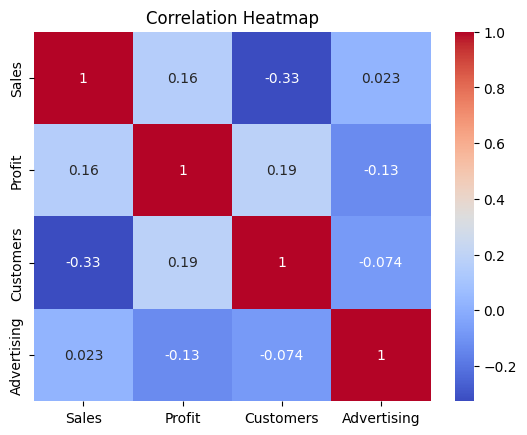

In [ ]:
sns.heatmap(corr, annot=True, cmap = 'coolwarm')

plt.title("Correlation Heatmap")
plt.show()

###What happens
- colors represent correlation strength
- numbers show exact values
- easy to compare all variables

#  **How to Read Heatmaps and Scatter Plots (Simple Mental Model)**

---

## 1.  How to Read a Heatmap (Correlation Colors)

---

###  First Principle

A heatmap is NOT about colors first.

It is about:

> “Numbers (correlation values) disguised as colors”

---

###  Step 1: Ignore colors first

Always first look at the numbers:

| Value | Meaning |
|------|--------|
| +1   | Strong positive relationship |
| 0.7  | Strong positive |
| 0.3  | Weak positive |
| 0    | No relationship |
| -0.5 | Negative relationship |
| -1   | Strong negative |

---

###  Step 2: Now understand colors

Colors are just a visual shortcut:

| Color Type | Meaning |
|------------|--------|
| Dark red / dark blue | Strong relationship |
| Light colors | Weak relationship |

---

###  Simple Rule

> Dark = strong  
> Light = weak  

---

###  Example Interpretation

If you see:

- Sales vs Profit = dark color → strong relationship  
- Sales vs Customers = light color → weak relationship  

 That’s the full meaning

---

## 2. How to Read Scatter Plots (VERY IMPORTANT)

---

###  First Principle

Scatter plots show:

> Relationship between two variables using points

---

##  Step 1: Look at the direction

### 1. Upward trend (↗)

- as X increases → Y increases  
 Positive relationship

---

### 2. Downward trend (↘)

- as X increases → Y decreases  
Negative relationship

---

### 3. Random cloud

- no pattern  
 No relationship

---

## Step 2: Look at tightness

| Pattern | Meaning |
|--------|--------|
| Points close to line | Strong relationship |
| Spread out points | Weak relationship |

---

##  Example

- tight upward line → strong positive correlation  
- scattered points → weak or no correlation  

---

## 3.  Why You Feel Confused (Important Insight)

---

Because you are doing this:

> Trying to understand ALL plots at once

But professionals do this:

---

###  They follow a system:

### Step 1: Heatmap (big picture)
- which variables matter?

### Step 2: Scatter plot (detail view)
- how exactly do they relate?

---

## 4.  Simple Mental Workflow

---

###  Always follow this:

### 1. Heatmap → “What matters?”
Find strong relationships.

---

### 2. Scatter plot → “How does it behave?”
Understand shape of relationship.

---

###  Example

Heatmap shows:

> Sales ↔ Profit = strong correlation

Then scatter plot shows:

> clear upward line

---

## 5.  Final Simplified Rule

---

### Heatmap = overview

> “Which variables are important?”

---

### Scatter plot = detail

> “How exactly do they behave?”

---

##  Final Insight

You are not supposed to “memorize colors or plots”.

You are supposed to build this thinking:

> “First find relationships (heatmap), then understand them (scatter)”

---

If you want next, I can:

 give you a **visual mental cheat sheet** for all Seaborn plots (very powerful for exams + interviews + projects)

##6. Understanding the Heatmap
 What to look for
###1. Strong Positive Correlation
- values close to +1
- dark/high intensity color

####Example insight:

“Sales and Profit are strongly related”

###2. Strong Negative Correlation
- values close to -1

#### Example insight:

“Cost increases while profit decreases”

###3. Weak or No Relationship
- values near 0

#### Example insight:

“Advertising has little impact on customers”

##7. Why Heatmap is Powerful
###Without Heatmap
- you check correlations one by one
- slow and confusing
###With Heatmap
- see all relationships at once
- quickly identify important variables

Instant overview of entire dataset relationships

##8. When to Use heatmap()
###Use when:
- you want to understand correlations
- you are doing feature analysis
- you are preparing for machine learning
### Avoid when:
- data is non-numeric
- dataset is too small (not meaningful)

##9. Common Mistakes
### Mistake 1: Misinterpreting correlation

Correlation ≠ causation

### Mistake 2: Ignoring scale

Even moderate correlation (0.5–0.7) can be important

### Mistake 3: Not using annot=True

Without values → hard to interpret

# **5.  `countplot()` — Categorical Data Analysis**

---

## 1. Why `countplot()` Exists

In real-world datasets, not everything is numerical.

A large part of data is **categorical**, such as:

- Region (East, West, North, South)  
- Gender (Male, Female)  
- Product category (A, B, C)  
- Customer type (New, Returning)

---

##  Core Problem

Before analysis, we often need to answer:

> “How many records belong to each category?”

---

##  That is exactly what `countplot()` does

---

## 2. What is `countplot()`?

---

###  Definition

`countplot()` shows:

> The number of occurrences of each category

---

###  Simple Meaning

It answers:

> “How many times does each category appear in the dataset?”

---

## 3. Example Dataset

---

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Region": ["East", "West", "East", "North", "West", "East", "South", "South", "West", "North"]
})

##4. Basic countplot() Example

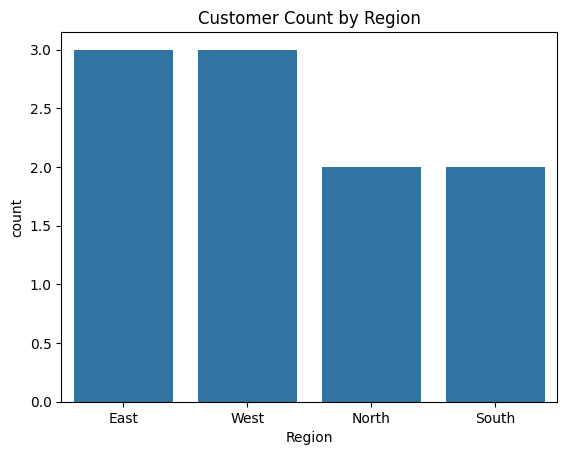

In [ ]:
sns.countplot(x = 'Region', data =df)

plt.title("Customer Count by Region")
plt.show()

###What is happening?
- Seaborn counts each category automatically
- Then displays it as bars

##5. How to Read a Countplot
### Step-by-step interpretation
####1. Look at height of bars
- Taller bar → more frequency
- Shorter bar → less frequency
####2. Compare categories

Example:

- West has highest customers
- South has lowest customers
### Insight

You immediately understand category distribution

##6. Why countplot() is Important
### Real-world use cases
- Customer distribution
- Product demand analysis
- Region-wise sales frequency
- Survey responses
### Business Insight Example

If:

- West region has highest count

 You might focus marketing there

##7. countplot() with hue
###Purpose

To compare categories within categories

### Example

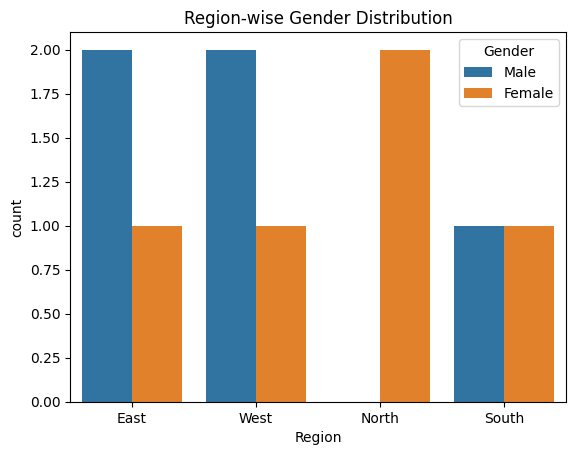

In [ ]:
df['Gender'] = ['Male', 'Female'] * 5
sns.countplot(x = 'Region', hue = 'Gender', data = df)

plt.title("Region-wise Gender Distribution")
plt.show()

##8. When to Use countplot()
### Use when:
- analyzing categorical variables
- understanding distribution of groups
- comparing frequencies
### Avoid when:
- working with continuous numerical data
- trying to show relationships between variables

##9. Common Mistakes
### Mistake 1: Using for numerical data

Wrong:

using countplot for Sales, Profit, etc.

### Mistake 2: Misreading bars
Height = frequency
NOT value magnitude
### Mistake 3: Ignoring imbalance

Unequal bars often contain important insights

# **6.  Advanced Distribution Analysis**

---

## 1. Why Distribution Analysis Matters

Before you build models or draw conclusions, you must understand:

> “How is my data actually distributed?”

Because most real-world insights depend on **data shape**, not just values.

---

##  Core Idea

Distribution analysis helps you understand:

- where most values lie  
- how spread out the data is  
- whether data is balanced or biased  

---

## 2. What is a Distribution?

---

###  Simple Definition

A distribution shows:

> “How frequently different values occur in a dataset”

---

###  Example Thinking

If you have sales data:

- Are most sales low?
- Are most sales high?
- Are values evenly spread?

---

## 3. What is KDE (Kernel Density Estimation)?

---

###  Definition

KDE is a smooth version of a histogram that shows:

> The probability density of data instead of raw counts

---

###  Simple Understanding

- Histogram → blocks (rough view)  
- KDE → smooth curve (clean pattern view)  

---

###  Why KDE is Useful

It helps you see:

- shape of distribution  
- peaks more clearly  
- overall pattern without noise  

---

## 4. Example: Histogram + KDE
###Histogram + KDE Plot
---



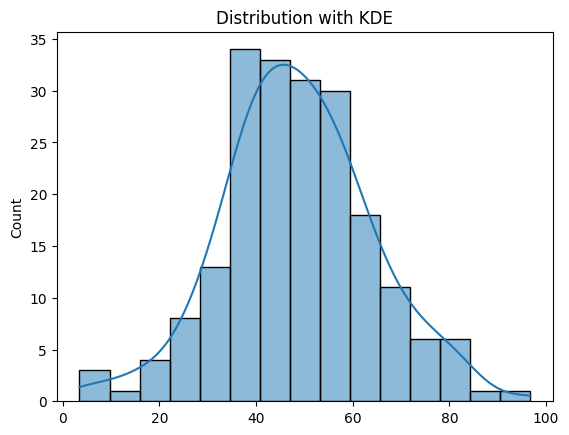

In [ ]:
data = np.random.normal(loc=50, scale=15, size=200)

sns.histplot(data, kde = True)

plt.title("Distribution with KDE")
plt.show()

###What you see
- bars = frequency
- line = smooth distribution shape

##5. Understanding Skewness
###Definition

Skewness tells you:

Whether data is balanced or leaning to one side

##Types of Skewness
###1. Normal Distribution (Balanced)
- symmetric shape
- center peak
###2. Right Skew (Positive Skew)
- long tail on right
- most values are small
###3. Left Skew (Negative Skew)
- long tail on left
- most values are high

###Insight

Skewness tells you:

- data imbalance
- presence of extreme values

##6. Multimodal Distributions
### Definition

A multimodal distribution has:

###More than one peak

#### Meaning
- multiple groups exist in data
- different behaviors are mixed
### Example Insight
- one peak = low-income customers
- second peak = high-income customers
### Business Meaning

Your data may contain hidden segments

##7. Data Concentration Patterns
### What it means

Where most data points are located:

- tightly packed → strong concentration
- widely spread → high variability
### Insight Examples
- Most customers spend between 20–40
- Few customers spend very high amounts

##8. Why Distribution Analysis is Critical
###It helps you:
- understand data behavior before modeling
- detect outliers
- identify bias in dataset
- choose correct machine learning algorithms
##9. Common Mistakes
### Mistake 1: Ignoring distribution

Jumping directly into plots or models

### Mistake 2: Misreading histogram

Thinking bars = exact values instead of frequency

### Mistake 3: Ignoring skewness

Skewness affects model performance heavily

# **7. Insight Extraction & Interpretation (MOST IMPORTANT)**

---

## 1. Why This Topic is the Most Important

Everything you learned so far:

- line plots  
- bar charts  
- scatter plots  
- heatmaps  
- pairplots  

 is useless if you cannot answer:

> “So what does this mean for the business?”

---

## Core Truth

> Data visualization is not about plots  
> It is about **decisions and insights**

---

## 2. Descriptive vs Analytical Thinking

---

###  Descriptive (Beginner Level)

> “Sales increased from 100 to 200”

---

###  Problem

- just stating what is visible  
- no value for decision-making  

---

###  Analytical (Professional Level)

> “Sales doubled over the period, indicating strong growth, possibly due to increased demand or successful marketing efforts”

---

###  Difference

| Level | Focus |
|------|------|
| Descriptive | What happened |
| Analytical | Why it happened + what it means |

---

## 3. How to Convert a Plot into Insight

---

##  Use This 3-Step Framework

---

### Step 1: Observe

> What do you see?

---

### Step 2: Interpret

> Why is this happening?

---

### Step 3: Conclude

> What does this mean for business?

---

---

## 4. Example 1 — Line Plot (Trend)

---

##  Observation

Sales increase steadily over time

---

##  Interpretation

Consistent growth indicates increasing demand

---

##  Insight

> Sales are growing consistently, suggesting strong market demand and effective strategy

---

---

## 5. Example 2 — Bar Plot (Comparison)

---

##  Observation

Category A has highest sales

---

##  Interpretation

Category A is outperforming others

---

##  Insight

> Category A is the top-performing segment and should be prioritized for further investment

---

---

## 6. Example 3 — Scatter Plot (Relationship)

---

##  Observation

Sales and Profit show upward trend

---

##  Interpretation

Higher sales lead to higher profit

---

##  Insight

> There is a strong positive relationship between sales and profit, indicating scalable profitability

---

---

## 7. Example 4 — Heatmap (Correlation)

---

##  Observation

Sales and Advertising have high correlation

---

##  Interpretation

Advertising likely influences sales

---

##  Insight

> Advertising has a strong impact on sales and should be optimized to drive growth

---

---

## 8. Writing Professional Insights

---

##  Structure

Use this format:

```text
Observation → Interpretation → Business Insight

###Example
Sales increased sharply in the last quarter, indicating a strong upward trend, which suggests that recent marketing strategies are effective and should be continued or expanded.

##9. Avoiding “Descriptive-Only” Analysis
### Weak Statements
- “There is a line going up”
- “Category A is higher”
- “Points are scattered”
### Why they are bad
- no meaning
- no decision value
### Strong Statements
- explain the reason
- connect to business
- suggest implication

##10. Analyst Thinking Framework

Whenever you see a plot, ask:

1. What pattern do I see?
2. Why might this pattern exist?
3. What decision can be made?

##11. Common Mistakes
### Mistake 1: Stopping at observation
### Mistake 2: Over-interpreting

Assuming cause without evidence

###Mistake 3: Ignoring business context

# **8. Analytical Thinking Framework**

---

## 1. Why This Framework Matters

At a professional level, your job is not to:

- create plots  
- describe visuals  

Your job is to:

> explain what the data means and what should be done next

---

## Core Principle

Visualization is only a tool.

> The real value comes from structured thinking and explanation

---

## 2. The Shift: From Visualization to Explanation

---

## Before (Beginner Level)

- “This is a line chart”
- “Sales are increasing”
- “Category A is higher”

---

## After (Professional Level)

- “Sales are increasing steadily, indicating sustained demand growth, which suggests expansion opportunities”

---

## Key Difference

| Level | Output |
|------|--------|
| Beginner | Description |
| Professional | Explanation + Decision |

---

## 3. The 3-Step Analytical Thinking Framework

---

## Step 1: Identify the Pattern

Ask:

> What pattern exists?

---

### What to look for

- trends (increasing / decreasing)  
- differences (which is higher/lower)  
- relationships (positive / negative)  
- distribution (spread, skewness)  

---

### Example

- Sales are increasing over time  
- Category A has highest performance  
- Sales and profit move together  

---

---

## Step 2: Explain the Pattern

Ask:

> Why does this pattern exist?

---

### What to consider

- business context  
- external factors (marketing, seasonality, pricing)  
- operational factors (efficiency, demand, strategy)  

---

### Example

- Sales increased due to higher demand  
- Category A performs better due to strong market preference  
- Profit rises with sales because margins are stable  

---

---

## Step 3: Derive a Decision

Ask:

> What decision can be made?

---

### What to focus on

- action  
- recommendation  
- business impact  

---

### Example

- Increase investment in high-performing categories  
- Expand marketing in growing regions  
- optimize pricing for better profit  

---

## 4. Putting It All Together

---

## Example 1 (Trend Analysis)

**Observation**

Sales increase steadily over time  

**Explanation**

Indicates consistent demand growth  

**Decision**

Expand production or inventory to meet demand  

---

## Example 2 (Comparison)

**Observation**

Category A outperforms others  

**Explanation**

Likely driven by customer preference or better positioning  

**Decision**

Focus resources on Category A and replicate its strategy  

---

## Example 3 (Relationship)

**Observation**

Sales and profit have strong positive relationship  

**Explanation**

Higher sales directly contribute to higher profitability  

**Decision**

Scale sales efforts to maximize profit  

---

## 5. Structured Insight Template (Portfolio-Ready)

---

Use this format in your notebooks:

```text
Observation:
[What you see]

Explanation:
[Why it happens]

Business Insight:
[What it means]

Recommendation:
[What should be done]

##6. Common Mistakes
###Mistake 1: Stopping at observation
only describing the chart
###Mistake 2: Guessing without logic
making assumptions without reasoning
###Mistake 3: No decision
analysis without actionable output

##7. Analyst Thinking Checklist

Before finalizing any analysis, ensure:

- You identified the pattern
- You explained the reason
- You provided a decision

##8. Final Insight

A professional data analyst does not deliver charts.

They deliver explanations, insights, and decisions supported by data

##9. One-Line Rule

Every visualization must answer:
####What happened, why it happened, and what should be done

# **9. Common Mistakes in Advanced Visualization**

---

## 1. Why This Topic Matters

At an advanced level, the biggest risk is not incorrect code.

It is:

> Drawing wrong conclusions from correct visuals

---

## Core Principle

> A visualization is only as good as its interpretation

---

## 2. Misinterpreting Correlation as Causation

---

### The Mistake

Seeing a relationship and assuming:

> “One variable causes the other”

---

###  Example

- Sales and Advertising are highly correlated  

---

###  Wrong Conclusion

> “Advertising causes sales to increase”

---

###  Correct Thinking

> “Sales and advertising move together, but further analysis is needed to confirm causation”

---

###  Key Rule

> Correlation shows relationship, not cause

---

## 3. Overloading Plots with Too Many Variables

---

###  The Mistake

Trying to include:

- too many categories  
- too many colors  
- too many dimensions  

---

###  Result

- confusing visualization  
- hard to interpret  
- no clear insight  

---

###  Correct Approach

- focus on 2–3 variables at a time  
- simplify visualization  
- prioritize clarity over complexity  

---

###  Key Rule

> A simple clear plot is better than a complex confusing one

---

## 4. Ignoring Data Context

---

###  The Mistake

Analyzing data without understanding:

- business background  
- data source  
- external factors  

---

###  Example

Sales drop observed

---

###  Wrong Interpretation

> “Business is failing”

---

###  Correct Thinking

> “Sales dropped, possibly due to seasonal variation or external factors”

---

###  Key Rule

> Data without context leads to wrong conclusions

---

## 5. Drawing Conclusions Without Evidence

---

###  The Mistake

Making strong claims from weak patterns

---

###  Example

- slight upward trend in scatter plot  

---

###  Wrong Conclusion

> “There is a strong relationship”

---

###  Correct Thinking

> “There may be a weak relationship, further analysis is required”

---

###  Key Rule

> Conclusions must match the strength of evidence

---

## 6. Additional Subtle Mistakes (Advanced Level)

---

###  Ignoring Outliers

- extreme values can distort analysis  

---

###  Misleading Scales

- improper axis scaling can exaggerate trends  

---

###  Over-reliance on Visuals

- not validating with statistics  

---

## 7. Analyst Thinking Upgrade

---

###  Before

> “I created and interpreted charts”

---

###  Now

> “I critically evaluate visualizations before making conclusions”

---

## 8. Professional Checklist

---

Before finalizing any insight, ask:

```text
1. Am I confusing correlation with causation?
2. Is my visualization clear or overloaded?
3. Do I understand the context of the data?
4. Is my conclusion supported by evidence?

##9. Final Insight

The most dangerous mistake is not wrong plotting.

It is confident interpretation of incomplete understanding

##10. One-Line Rule

Always question your visualization before trusting it